# Avito Demand Prediction

Задача исследования - изучить объявления Avito и определить особенности данных, влияющие на настройку AutoML для прогноза `deal_probability`. Целевая переменная принимает значения от 0 до 1. Рассматривается задача регрессии.

Источник: [Avito Demand Prediction (Kaggle)](https://www.kaggle.com/competitions/avito-demand-prediction/data). Расчёты и выводы представлены в `EDA_avito_demand_prediction.md`.

Шесть архивов [train.zip](https://drive.google.com/file/d/1m21RAnI2Y4lp3xKptsgFlhWzO_p__AkL/view?usp=drive_link), [test.zip](https://drive.google.com/file/d/1JRCjD_iyju0Fh9NtB_WekKxuO3oE_Pgf/view?usp=drive_link), [train_active.zip](https://drive.google.com/file/d/1old2ma3Ks_KOG7Z_-AwZ_ZR4QKREisRR/view?usp=drive_link), [test_active.zip](https://drive.google.com/file/d/13o-l3huxjHvFtZx2VM-GO8UW5ZqhKXve/view?usp=drive_link), [periods_train.zip](https://drive.google.com/file/d/1AUIoJ_ptI4Id6963LSm-_UQBUydRruhP/view?usp=drive_link), [periods_test.zip](https://drive.google.com/file/d/1MaX6YHuESEi0iWa17l-B5tc3lE8ev5kW/view?usp=drive_link) размещаются рядом с ноутбуком. В каждом архиве находится один одноимённый CSV-файл. Ячейки выполняются последовательно сверху вниз.

## 1. Первичный анализ

Проверяются состав основных таблиц, целевая переменная, типы данных и уникальность идентификаторов.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

names = ["train", "test", "train_active", "test_active", "periods_train", "periods_test"]
files = {name: Path(f"{name}.zip") for name in names}
missing_files = [str(path) for path in files.values() if not path.is_file()]
assert not missing_files, f"Не найдены архивы: {', '.join(missing_files)}"

display(pd.Series(files, name="Архив").to_frame())
res = {}

,Архив
train,train.zip
test,test.zip
train_active,train_active.zip
test_active,test_active.zip
periods_train,periods_train.zip
periods_test,periods_test.zip


In [2]:
id_types = {"item_id": "string", "user_id": "string", "image_top_1": "string"}
train = pd.read_csv(files["train"], parse_dates=["activation_date"],
                    dtype=id_types, low_memory=False)
test = pd.read_csv(files["test"], parse_dates=["activation_date"],
                   dtype=id_types, low_memory=False)
res["shape_train"] = train.shape
res["shape_test"] = test.shape
print("Train:", train.shape, "Test:", test.shape)
print("Цель только в train:", "deal_probability" in train and "deal_probability" not in test)
print("Совпадение остальных столбцов:", set(train.columns) - {"deal_probability"} == set(test.columns))
display(train.head(3))

Train: (1503424, 18) Test: (508438, 17)
Цель только в train: True
Совпадение остальных столбцов: True


,item_id,user_id,region,city,parent_category_name,category_name,param_1,param_2,param_3,title,description,price,item_seq_number,activation_date,user_type,image,image_top_1,deal_probability
0,b912c3c6a6ad,e00f8ff2eaf9,Свердловская область,Екатеринбург,Личные вещи,Товары для детей и игрушки,Постельные принадлежности,NaN,NaN,Кокоби(кокон для сна),"Кокон для сна малыша,пользовались меньше месяц...",400.0,2,2017-03-28,Private,d10c7e016e03247a3bf2d13348fe959fe6f436c1caf64c...,1008.0,0.12789
1,2dac0150717d,39aeb48f0017,Самарская область,Самара,Для дома и дачи,Мебель и интерьер,Другое,NaN,NaN,Стойка для Одежды,"Стойка для одежды, под вешалки. С бутика.",3000.0,19,2017-03-26,Private,79c9392cc51a9c81c6eb91eceb8e552171db39d7142700...,692.0,0.00000
2,ba83aefab5dc,91e2f88dd6e3,Ростовская область,Ростов-на-Дону,Бытовая электроника,Аудио и видео,"Видео, DVD и Blu-ray плееры",NaN,NaN,Philips bluray,"В хорошем состоянии, домашний кинотеатр с blu ...",4000.0,9,2017-03-20,Private,b7f250ee3f39e1fedd77c141f273703f4a9be59db4b48a...,3032.0,0.43177


In [3]:
print("Типы столбцов train:")
display(train.dtypes.astype(str).value_counts().to_frame("Количество"))
print("Повторы item_id в train:", train["item_id"].duplicated().sum())
print("Повторы item_id в test:", test["item_id"].duplicated().sum())
print("Пересечения item_id:", train["item_id"].isin(test["item_id"]).sum())
print("Полные дубликаты train:", train.duplicated().sum())
print("Пропуски таргета:", train["deal_probability"].isna().sum())
res["id_duplicate_train"] = int(train["item_id"].duplicated().sum())
res["id_duplicate_test"] = int(test["item_id"].duplicated().sum())
res["id_overlap"] = int(train["item_id"].isin(test["item_id"]).sum())

Типы столбцов train:


,Количество
str,11
string,3
float64,2
int64,1
datetime64[us],1


Повторы item_id в train: 0
Повторы item_id в test: 0
Пересечения item_id: 0
Полные дубликаты train: 0
Пропуски таргета: 0


## 2. Распределение целевой переменной

`deal_probability` - числовая целевая переменная в интервале от 0 до 1. Важно различать регрессию с большим количеством нулей и бинарную классификацию.

In [4]:
target = train["deal_probability"]
target_stats = {
    "Нули": int(target.eq(0).sum()),
    "Единицы": int(target.eq(1).sum()),
    "Между 0 и 1": int(target.gt(0).mul(target.lt(1)).sum()),
    "Вне [0, 1]": int((target.lt(0) | target.gt(1)).sum()),
    "Пропуски": int(target.isna().sum()),
    "Различных значений": int(target.nunique()),
    "Среднее": float(target.mean()),
    "Медиана": float(target.median()),
}
res["target"] = target_stats
display(pd.Series(target_stats, name="Значение").to_frame())
print("Доля нулей, %:", round(100 * target.eq(0).mean(), 2))
print("Доля единиц, %:", round(100 * target.eq(1).mean(), 2))

,Значение
Нули,974618.000000
Единицы,10076.000000
Между 0 и 1,518730.000000
"Вне [0, 1]",0.000000
Пропуски,0.000000
Различных значений,18407.000000
Среднее,0.139131
Медиана,0.000000


Доля нулей, %: 64.83
Доля единиц, %: 0.67


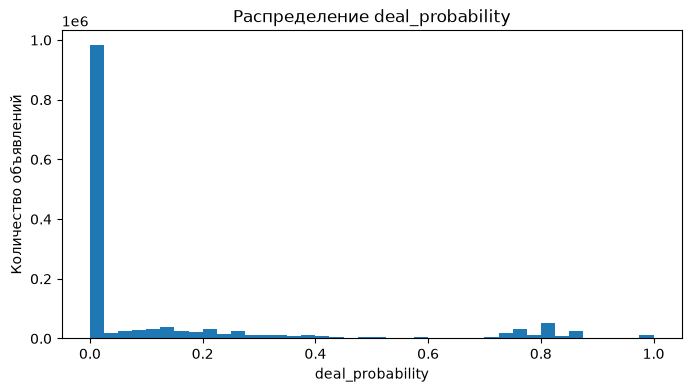

In [5]:
plt.figure(figsize=(8, 4))
plt.hist(target.dropna(), bins=40)
plt.title("Распределение deal_probability")
plt.xlabel("deal_probability")
plt.ylabel("Количество объявлений")
plt.show()

In [6]:
category_target = (train.groupby("parent_category_name", dropna=False)
                   .agg(Объявлений=("deal_probability", "size"),
                        Среднее=("deal_probability", "mean"),
                        Доля_нулей=("deal_probability", lambda x: 100 * x.eq(0).mean()))
                   .sort_values("Объявлений", ascending=False))
res["category_target"] = category_target
print("Целевая переменная по родительским категориям:")
display(category_target.round(3))

Целевая переменная по родительским категориям:


,Объявлений,Среднее,Доля_нулей
parent_category_name,,,
Личные вещи,697623,0.076,82.636
Для дома и дачи,178823,0.180,63.141
Бытовая электроника,173008,0.175,58.529
Недвижимость,153190,0.142,30.913
Хобби и отдых,86011,0.124,73.305
Транспорт,79839,0.263,32.760
Услуги,64385,0.403,23.662
Животные,52470,0.236,42.428
Для бизнеса,18075,0.111,54.788


## 3. Пропуски и структура категорий

Доли пропусков рассчитываются по всем признакам основной таблицы. Проверяется, связана ли заполненность категориальных параметров с типом объявления.

In [7]:
missing_train = (100 * train.isna().mean()).sort_values(ascending=False)
missing_test = (100 * test.isna().mean()).sort_values(ascending=False)
shared = [c for c in test.columns if c in train.columns]
missing_table = pd.DataFrame({"train, %": missing_train.reindex(shared),
                              "test, %": missing_test.reindex(shared)})
missing_table["Разница, п.п."] = missing_table["test, %"] - missing_table["train, %"]
res["missing_train"] = missing_train
res["missing_table"] = missing_table
print("Столбцов с пропусками в train:", int((missing_train > 0).sum()))
print("Столбцов с >50% пропусков в train:", int((missing_train > 50).sum()))
display(missing_table.loc[missing_table["train, %"].sort_values(ascending=False).index].round(2))

Столбцов с пропусками в train: 7
Столбцов с >50% пропусков в train: 1


,"train, %","test, %","Разница, п.п."
param_3,57.37,60.25,2.88
param_2,43.54,45.87,2.33
description,7.73,0.00,-7.73
image,7.49,8.38,0.89
image_top_1,7.49,8.38,0.89
price,5.68,6.02,0.34
param_1,4.10,4.51,0.41
item_id,0.00,0.00,0.00
user_id,0.00,0.00,0.00
category_name,0.00,0.00,0.00


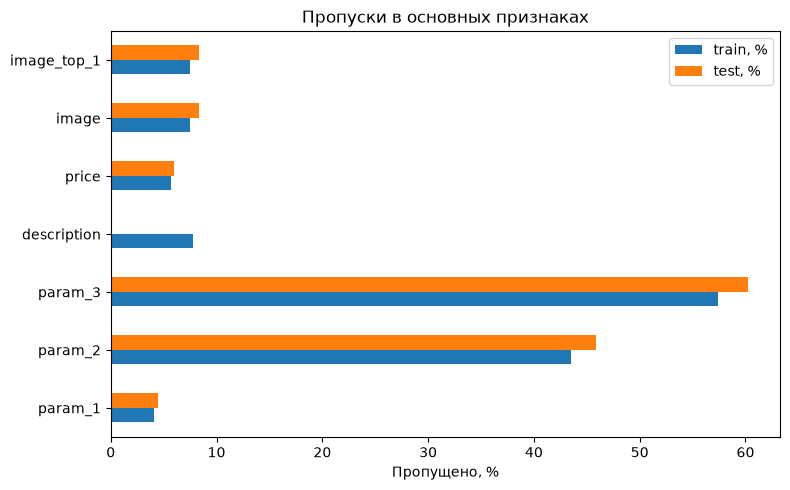

In [8]:
selected_missing = ["param_1", "param_2", "param_3", "description",
                    "price", "image", "image_top_1"]
missing_table.loc[selected_missing, ["train, %", "test, %"]].plot.barh(figsize=(8, 5))
plt.title("Пропуски в основных признаках")
plt.xlabel("Пропущено, %")
plt.tight_layout()
plt.show()

In [9]:
param3_by_parent = (train.groupby("parent_category_name")
                    .agg(Объявлений=("item_id", "size"),
                         Пропуски_param3=("param_3", lambda s: 100 * s.isna().mean()))
                    .sort_values("Пропуски_param3", ascending=False))
res["param3_by_parent"] = param3_by_parent
display(param3_by_parent.round(2))

,Объявлений,Пропуски_param3
parent_category_name,,
Бытовая электроника,173008,100.00
Для бизнеса,18075,100.00
Для дома и дачи,178823,100.00
Животные,52470,100.00
Хобби и отдых,86011,100.00
Услуги,64385,100.00
Недвижимость,153190,39.77
Личные вещи,697623,30.24
Транспорт,79839,22.42


In [10]:
features = ["region", "city", "parent_category_name", "category_name", "param_1",
            "param_2", "param_3", "user_type", "image_top_1", "user_id"]
cardinality = pd.DataFrame({
    "train": [train[c].nunique(dropna=True) for c in features],
    "test": [test[c].nunique(dropna=True) for c in features]
}, index=features)
res["cardinality"] = cardinality
display(cardinality)

,train,test
region,28,28
city,1733,1644
parent_category_name,9,9
category_name,47,47
param_1,371,361
param_2,271,255
param_3,1219,973
user_type,3,3
image_top_1,3062,3047
user_id,771769,306069


## 4. Цены, числовые и текстовые признаки

Проверяются пропуски, крайние значения, размеры текстовых полей и их фактическая доступность. Идентификатор фотографии не является её содержимым.

In [11]:
price_summary = pd.DataFrame({
    "train": train["price"].describe(percentiles=[.5, .9, .99, .999]),
    "test": test["price"].describe(percentiles=[.5, .9, .99, .999])
})
res["price_summary"] = price_summary
print("Нулевых цен train:", int(train["price"].eq(0).sum()))
print("Отрицательных цен train:", int(train["price"].lt(0).sum()))
display(price_summary.round(2))

Нулевых цен train: 4646
Отрицательных цен train: 0


,train,test
count,1.418062e+06,4.778530e+05
mean,3.167081e+05,2.798190e+05
std,6.689154e+07,5.364218e+06
min,0.000000e+00,0.000000e+00
50%,1.300000e+03,1.500000e+03
90%,2.500000e+05,3.500000e+05
99%,4.050000e+06,4.200000e+06
99.9%,1.900000e+07,2.000000e+07
max,7.950101e+10,3.000060e+09


In [12]:
category_price = train.groupby("parent_category_name").agg(
    Объявлений=("price", "size"),
    Известных_цен=("price", "count"),
    Медиана=("price", "median"),
    P99=("price", lambda x: x.quantile(.99))
).sort_values("Объявлений", ascending=False)
res["category_price"] = category_price
display(category_price.round(2))

,Объявлений,Известных_цен,Медиана,P99
parent_category_name,,,,
Личные вещи,697623,686389,700.0,18000.0
Для дома и дачи,178823,168689,2000.0,87000.0
Бытовая электроника,173008,168845,2500.0,47000.0
Недвижимость,153190,139433,1300000.0,17984000.0
Хобби и отдых,86011,80805,1500.0,72999.6
Транспорт,79839,77348,220000.0,3200000.0
Услуги,64385,42151,500.0,50300.0
Животные,52470,38833,1000.0,75000.0
Для бизнеса,18075,15569,20000.0,7350960.0


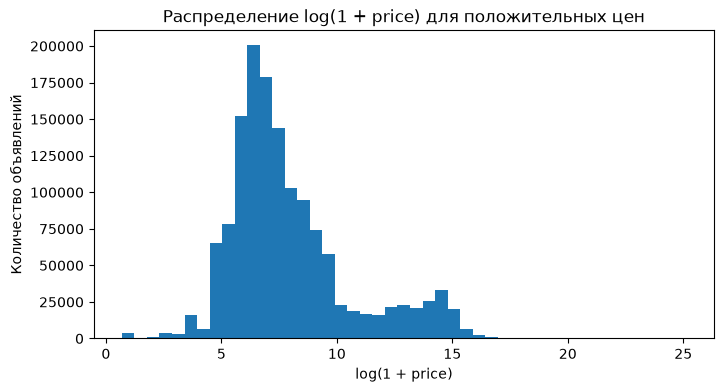

In [13]:
positive_price = train.loc[train["price"].gt(0), "price"].dropna()
plt.figure(figsize=(8, 4))
plt.hist(np.log1p(positive_price), bins=45)
plt.title("Распределение log(1 + price) для положительных цен")
plt.xlabel("log(1 + price)")
plt.ylabel("Количество объявлений")
plt.show()

In [14]:
text_summary = {}
for name in ["title", "description"]:
    for df_name, df in [("train", train), ("test", test)]:
        lengths = df[name].str.len()
        text_summary[(name, df_name)] = {
            "С пропуском": int(df[name].isna().sum()),
            "Медиана длины": float(lengths.median()),
            "P90 длины": float(lengths.quantile(.9)),
            "P99 длины": float(lengths.quantile(.99))
        }
res["text_summary"] = text_summary
display(pd.DataFrame.from_dict(text_summary, orient="index"))
print("Изображения без ID в train:", int(train["image"].isna().sum()))
print("Кодов image_top_1 в train:", int(train["image_top_1"].nunique()))

С пропуском  Медиана длины  P90 длины  P99 длины
title       train            0           20.0       37.0      50.00
            test             0           20.0       37.0      50.00
description train       116276           96.0      444.0    1564.53
            test             0           95.0      446.0    1542.00

Изображения без ID в train: 112588
Кодов image_top_1 в train: 3062


## 5. Продавцы, повторные объявления и временная структура

Один продавец может иметь несколько объявлений. Учитываются временные границы, возможность повторных наблюдений и различия между прогнозом будущих объявлений и прогнозом для новых продавцов.

In [15]:
train_users = set(train["user_id"].dropna().unique())
test_users = set(test["user_id"].dropna().unique())
user_overlap = len(train_users.intersection(test_users))
res["users"] = {"train":len(train_users), "test":len(test_users), "overlap":user_overlap}
print("Продавцов train:", len(train_users))
print("Продавцов test:", len(test_users))
print("Пересечение продавцов:", user_overlap)
print("Повторных объявлений сверх одного на продавца train:", len(train) - len(train_users))
print("Максимум объявлений одного продавца train:", int(train["user_id"].value_counts().max()))

Продавцов train: 771769
Продавцов test: 306069
Пересечение продавцов: 67929
Повторных объявлений сверх одного на продавца train: 731655
Максимум объявлений одного продавца train: 1080


In [16]:
date_train = train.groupby("activation_date").agg(
    Объявлений=("item_id", "size"),
    Средняя_цель=("deal_probability", "mean"),
    Доля_нулей=("deal_probability", lambda x: 100 * x.eq(0).mean())
)
date_test = test.groupby("activation_date").size()
res["date_train"] = date_train
res["date_test"] = date_test
print("Диапазон дат train:", train["activation_date"].min(), train["activation_date"].max())
print("Диапазон дат test:", test["activation_date"].min(), test["activation_date"].max())
print("Количество дней train:", len(date_train), "test:", len(date_test))
display(date_train.round(3))
display(date_test.to_frame("Объявлений"))

Диапазон дат train: 2017-03-15 00:00:00 2017-04-07 00:00:00
Диапазон дат test: 2017-04-12 00:00:00 2017-04-20 00:00:00
Количество дней train: 21 test: 9


,Объявлений,Средняя_цель,Доля_нулей
activation_date,,,
2017-03-15,108615,0.140,64.320
2017-03-16,106168,0.141,64.033
2017-03-17,98773,0.141,63.905
2017-03-18,97554,0.140,65.750
2017-03-19,114416,0.138,66.979
2017-03-20,115190,0.138,64.522
2017-03-21,110535,0.139,64.124
2017-03-22,109813,0.139,63.910
2017-03-23,106544,0.137,64.521


,Объявлений
activation_date,
2017-04-12,81824
2017-04-13,77176
2017-04-14,70366
2017-04-15,58793
2017-04-16,58909
2017-04-17,80191
2017-04-18,81114
2017-04-19,64
2017-04-20,1


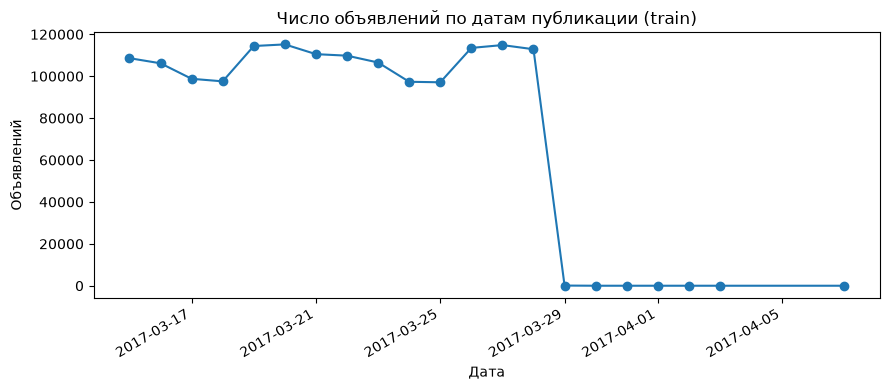

In [17]:
date_train["Объявлений"].plot(figsize=(9, 4), marker="o")
plt.title("Число объявлений по датам публикации (train)")
plt.xlabel("Дата")
plt.ylabel("Объявлений")
plt.tight_layout()
plt.show()

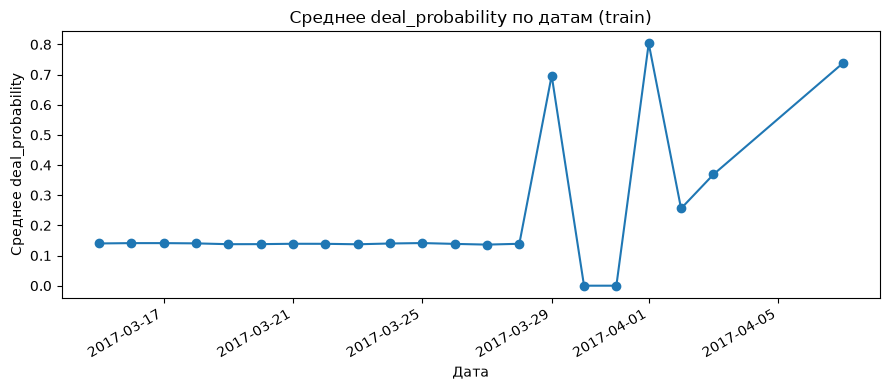

In [18]:
date_train["Средняя_цель"].plot(figsize=(9, 4), marker="o")
plt.title("Среднее deal_probability по датам (train)")
plt.xlabel("Дата")
plt.ylabel("Среднее deal_probability")
plt.tight_layout()
plt.show()

In [19]:
ordered_dates = train["activation_date"].sort_values().reset_index(drop=True)
cutoff_date = ordered_dates.iloc[int(.8 * len(ordered_dates))]
train_early = train["activation_date"] < cutoff_date
train_late = ~train_early
print("Иллюстративная граница хронологического holdout:", cutoff_date.date())
print("До границы:", int(train_early.sum()), "с границы:", int(train_late.sum()))
print("Средняя цель до/после:", round(train.loc[train_early, "deal_probability"].mean(), 5),
      round(train.loc[train_late, "deal_probability"].mean(), 5))
users_early = set(train.loc[train_early, "user_id"].dropna().unique())
users_late = set(train.loc[train_late, "user_id"].dropna().unique())
print("Продавцов, встречающихся в обеих временных частях:", len(users_early & users_late))
res["time_holdout"] = {"cutoff":str(cutoff_date.date()), "early":int(train_early.sum()),
    "late":int(train_late.sum()), "overlap_users":len(users_early & users_late)}

Иллюстративная граница хронологического holdout: 2017-03-26
До границы: 1162063 с границы: 341361
Средняя цель до/после: 0.13944 0.13808
Продавцов, встречающихся в обеих временных частях: 46145


## 6. Различия train/test

Сопоставление пропусков и значений выполняется на всех общих столбцах основных таблиц. Изменение распределения ещё не означает утечку или ухудшение качества прогноза.

In [20]:
print("Наибольшие отличия долей пропусков (п.п.):")
display(missing_table.reindex(
    missing_table["Разница, п.п."].abs().sort_values(ascending=False).index
).head(12).round(2))
cat_shift = {}
for col in ["parent_category_name", "category_name", "user_type", "region"]:
    tr = train[col].value_counts(normalize=True, dropna=False)
    te = test[col].value_counts(normalize=True, dropna=False)
    cat_shift[col] = (100 * (te - tr).fillna(0)).abs().max()
print("Максимальная разница долей категорий, п.п.:")
display(pd.Series(cat_shift, name="Максимум, п.п.").sort_values(ascending=False).round(2))
res["cat_shift"] = cat_shift

Наибольшие отличия долей пропусков (п.п.):


,"train, %","test, %","Разница, п.п."
description,7.73,0.00,-7.73
param_3,57.37,60.25,2.88
param_2,43.54,45.87,2.33
image,7.49,8.38,0.89
image_top_1,7.49,8.38,0.89
param_1,4.10,4.51,0.41
price,5.68,6.02,0.34
item_id,0.00,0.00,0.00
user_id,0.00,0.00,0.00
category_name,0.00,0.00,0.00


Максимальная разница долей категорий, п.п.:


parent_category_name    3.81
category_name           2.11
user_type               1.09
region                  0.74
Name: Максимум, п.п., dtype: float64

In [21]:
for col in ["user_type", "parent_category_name"]:
    shares = pd.DataFrame({
        "train, %": 100 * train[col].value_counts(normalize=True, dropna=False),
        "test, %": 100 * test[col].value_counts(normalize=True, dropna=False),
    }).fillna(0)
    shares["Разница, п.п."] = shares["test, %"] - shares["train, %"]
    print(col)
    display(shares.sort_values("train, %", ascending=False).round(2))

user_type


,"train, %","test, %","Разница, п.п."
user_type,,,
Private,71.55,70.46,-1.09
Company,23.10,23.59,0.49
Shop,5.35,5.95,0.59


parent_category_name


,"train, %","test, %","Разница, п.п."
parent_category_name,,,
Личные вещи,46.40,42.60,-3.81
Для дома и дачи,11.89,12.77,0.87
Бытовая электроника,11.51,11.46,-0.04
Недвижимость,10.19,11.29,1.10
Хобби и отдых,5.72,6.15,0.43
Транспорт,5.31,5.89,0.58
Услуги,4.28,4.65,0.36
Животные,3.49,3.93,0.44
Для бизнеса,1.20,1.27,0.07


In [22]:
for col in ["price", "item_seq_number"]:
    print(col, "train/test медиана:", train[col].median(), test[col].median(),
          "train/test P99:", train[col].quantile(.99), test[col].quantile(.99))

price train/test медиана: 1300.0 1500.0 train/test P99: 4050000.0 4200000.0
item_seq_number train/test медиана: 29.0 30.0 train/test P99: 19790.310000000056 22971.0


## 7. Связи признаков с целевой переменной

Анализируется статистическая связь, а не причинное влияние. Корреляции рассчитываются по всем доступным парам, график на фиксированной выборке объявлений.

In [23]:
for col in ["price", "item_seq_number"]:
    s = train[[col, "deal_probability"]].dropna()
    print(col, "пар:", len(s), "корреляция Пирсона:",
          round(s[col].corr(s["deal_probability"]), 5))
print("Средняя цель по user_type:")
display(train.groupby("user_type")["deal_probability"].agg(["size", "mean", "median"]).round(4))

price пар: 1418062 корреляция Пирсона: -0.0011
item_seq_number пар: 1503424 корреляция Пирсона: -0.03574
Средняя цель по user_type:


,size,mean,median
user_type,,,
Company,347249,0.1245,0.0
Private,1075706,0.1496,0.0
Shop,80469,0.0628,0.0


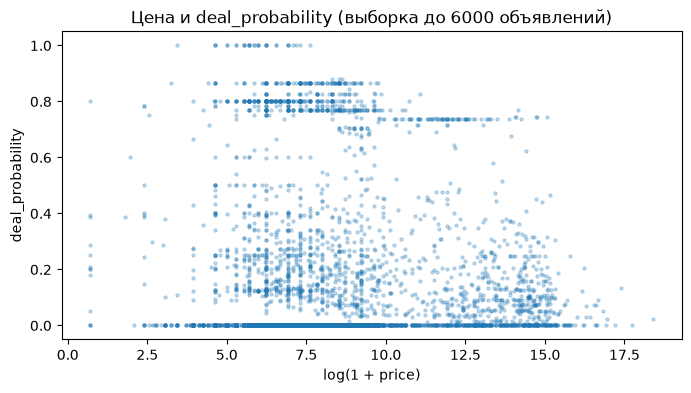

In [24]:
points = train.loc[train["price"].gt(0), ["price", "deal_probability"]].dropna()
points = points.sample(n=min(6000, len(points)), random_state=42)
plt.figure(figsize=(8, 4))
plt.scatter(np.log1p(points["price"]), points["deal_probability"], s=5, alpha=.25)
plt.title("Цена и deal_probability (выборка до 6000 объявлений)")
plt.xlabel("log(1 + price)")
plt.ylabel("deal_probability")
plt.show()

In [25]:
description_len = train["description"].str.len()
length_group = pd.cut(description_len, bins=[0, 20, 100, 300, 1000, np.inf],
                      include_lowest=True)
text_target = (train.groupby(length_group, observed=True)["deal_probability"]
               .agg(["size", "mean", "median"]))
print("Цель по длине описания (только заполненные описания):")
display(text_target.round(4))
print("Без описания:", int(description_len.isna().sum()),
      "средняя цель:", round(float(train.loc[description_len.isna(), "deal_probability"].mean()), 5))

Цель по длине описания (только заполненные описания):


,size,mean,median
description,,,
"(-0.001, 20.0]",88595,0.1110,0.0
"(20.0, 100.0]",630094,0.1357,0.0
"(100.0, 300.0]",446378,0.1644,0.0
"(300.0, 1000.0]",184975,0.1496,0.0
"(1000.0, inf]",37106,0.1052,0.0


Без описания: 116276 средняя цель: 0.07608


## 8. Дополнительные таблицы и связи

`train_active`, `test_active`, `periods_train` и `periods_test` исследуются по всем строкам. Для больших архивов используется потоковое чтение CSV. Точные пересечения `item_id` и `user_id` рассчитываются с помощью словарей Python, хранящих уникальные идентификаторы и битовые маски принадлежности таблицам. Квантили цен дополнительных таблиц являются выборочными оценками.

In [26]:
import zipfile
from collections import Counter

chunk_size = 40_000
ad_names = ["train", "test", "train_active", "test_active"]
period_names = ["periods_train", "periods_test"]
bits = {name: 1 << i for i, name in enumerate(names)}

csv_members = {}
for name in names:
    with zipfile.ZipFile(files[name]) as archive:
        csv_files = [m.filename for m in archive.infolist()
                     if not m.is_dir() and m.filename.lower().endswith(".csv")]
        assert len(csv_files) == 1, f"Ожидается ровно один CSV: {files[name]}"
        csv_members[name] = csv_files[0]
        with archive.open(csv_files[0]) as stream:
            columns = pd.read_csv(stream, nrows=0).columns.tolist()
        print(name, "столбцов:", len(columns), "CSV:", csv_files[0])

assert "deal_probability" in train and "deal_probability" not in test

train столбцов: 18 CSV: train.csv
test столбцов: 17 CSV: test.csv
train_active столбцов: 15 CSV: train_active.csv
test_active столбцов: 15 CSV: test_active.csv
periods_train столбцов: 4 CSV: periods_train.csv
periods_test столбцов: 4 CSV: periods_test.csv


In [27]:
# Ключ словаря - уникальный ID. Значение содержит маску таблиц и счётчики.
# Один словарь экономнее, чем отдельное множество для каждой таблицы.
item_state = {}
user_state = {}

item_mask_bits = (1 << len(names)) - 1
user_mask_bits = (1 << len(ad_names)) - 1

# Счётчики периодов упакованы в 16-битные поля после битовой маски.
period_shifts = {"periods_train": 8, "periods_test": 24}
period_count_mask = (1 << 16) - 1

# Счётчики объявлений продавца упакованы в поля по 20 бит.
user_shifts = {name: 4 + 20 * i for i, name in enumerate(ad_names)}
user_count_mask = (1 << 20) - 1


In [28]:
def register_identifiers(name, chunk):
    bit = bits[name]
    ids = chunk["item_id"].dropna().astype(str)

    if name in ad_names:
        # Только уникальные ID внутри фрагмента. Все фрагменты учитываются вместе.
        for item_id in set(ids):
            item_state[item_id] = item_state.get(item_id, 0) | bit

        shift = user_shifts[name]
        counts = chunk["user_id"].dropna().astype(str).value_counts(sort=False)
        for user_id, n in counts.items():
            old = user_state.get(user_id, 0)
            user_state[user_id] = (old | (1 << ad_names.index(name))) + (int(n) << shift)
    else:
        shift = period_shifts[name]
        counts = ids.value_counts(sort=False)
        for item_id, n in counts.items():
            old = item_state.get(item_id, 0)
            item_state[item_id] = (old | bit) + (int(n) << shift)

In [29]:
for name, data in [("train", train), ("test", test)]:
    for start in range(0, len(data), chunk_size):
        register_identifiers(name, data.iloc[start:start + chunk_size])
    print(name, "обработано строк:", len(data))


train обработано строк: 1503424
test обработано строк: 508438


In [30]:
class PriceSample:
    # Квантили оцениваются по фиксированной случайной подвыборке каждого чанка.
    def __init__(self, seed=2200):
        self.rng = np.random.default_rng(seed)
        self.values = []

    def add(self, series):
        values = pd.to_numeric(series, errors="coerce").dropna().to_numpy(dtype=float)
        values = values[np.isfinite(values)]
        if not len(values):
            return
        count = min(300, len(values))
        self.values.extend(values[self.rng.choice(len(values), count, replace=False)].tolist())
        if len(self.values) > 100_000:
            selected = self.rng.choice(len(self.values), 80_000, replace=False)
            self.values = [self.values[i] for i in selected]

    def summary(self):
        values = np.asarray(self.values)
        return {"sample_size": len(values),
                "median_approx": float(np.median(values)) if len(values) else None}


In [31]:
extra = {}
for name in ["train_active", "test_active", "periods_train", "periods_test"]:
    extra[name] = {
        "rows": 0, "missing": Counter(), "categories": Counter(),
        "start": None, "end": None, "daily": Counter(),
        "invalid_dates": 0, "price_zero": 0, "price_max": None,
        "price_sample": PriceSample(), "reversed_periods": 0,
        "duration_sum": 0, "duration_valid": 0,
        "missing_period_start": 0, "missing_period_end": 0,
        "start_before_activation": 0, "end_before_activation": 0,
    }


# Диагностика качества и доступности истории выполняется в том же проходе по ZIP.
expected_parents = set(train["parent_category_name"].dropna().astype(str))
expected_user_types = set(train["user_type"].dropna().astype(str))
first_target_date = {
    "train_active": train.groupby("user_id")["activation_date"].min().to_dict(),
    "test_active": test.groupby("user_id")["activation_date"].min().to_dict(),
}
quality = {}
for name in ["train_active", "test_active"]:
    quality[name] = {
        "without_region": 0, "without_geo_triplet": 0,
        "without_core_fields": 0, "without_date_but_region": 0,
        "invalid_parent": Counter(), "region_missing_users": Counter(),
        "examples": [], "bad_parent_examples": [], "well_formed": 0,
        "seller_rows": 0, "past_rows": 0, "past_sellers": set(),
    }

# Небольшая воспроизводимая выборка общих item_id для сверки двух снимков.
snapshot_rng = np.random.default_rng(731)
snapshot_train = {}
snapshot_matches = {"ids": set(), "different_date": 0,
                    "different_user": 0, "different_price": 0,
                    "examples": []}


In [32]:
def update_extra_basic(name, chunk):
    s = extra[name]
    s["rows"] += len(chunk)
    s["missing"].update(chunk.isna().sum().astype(int).to_dict())
    if "parent_category_name" in chunk:
        counts = chunk["parent_category_name"].value_counts(dropna=False)
        s["categories"].update({"<MISSING>" if pd.isna(k) else str(k): int(n)
                                for k, n in counts.items()})
    if "price" in chunk:
        price = pd.to_numeric(chunk["price"], errors="coerce")
        s["price_zero"] += int(price.eq(0).sum())
        if price.notna().any():
            maximum = float(price.max())
            s["price_max"] = max(s["price_max"], maximum) if s["price_max"] is not None else maximum
        s["price_sample"].add(price)


    if name in quality:
        q = quality[name]
        geo = chunk["region"].isna()
        geo3 = chunk[["region", "city", "parent_category_name"]].isna().all(axis=1)
        core = ["region", "city", "parent_category_name", "category_name",
                "title", "price", "item_seq_number", "activation_date", "user_type"]
        all_core = chunk[core].isna().all(axis=1)
        missing_date = chunk["activation_date"].isna()
        wrong_parent = chunk["parent_category_name"].notna() & ~chunk["parent_category_name"].isin(expected_parents)
        q["without_region"] += int(geo.sum())
        q["without_geo_triplet"] += int(geo3.sum())
        q["without_core_fields"] += int(all_core.sum())
        q["without_date_but_region"] += int((missing_date & ~geo).sum())
        q["region_missing_users"].update(
            chunk.loc[geo, "user_id"].fillna("<MISSING>").astype(str).value_counts().to_dict())
        q["invalid_parent"].update(
            chunk.loc[wrong_parent, "parent_category_name"].astype(str).value_counts().to_dict())

        columns = ["item_id", "user_id", "region", "city", "parent_category_name",
                   "category_name", "title", "item_seq_number", "activation_date", "user_type"]
        def keep_examples(mask, destination, limit=5):
            need = limit - len(destination)
            if need > 0:
                for _, row in chunk.loc[mask, columns].head(need).iterrows():
                    destination.append({c: "<NA>" if pd.isna(v) else str(v)
                                        for c, v in row.items()})
        keep_examples(geo | all_core, q["examples"])
        keep_examples(wrong_parent, q["bad_parent_examples"], 4)

        dates = pd.to_datetime(chunk["activation_date"], errors="coerce", format="%Y-%m-%d")
        well_formed = (chunk[["item_id", "user_id", "region", "city",
                              "category_name", "parent_category_name"]].notna().all(axis=1)
                       & chunk["parent_category_name"].isin(expected_parents)
                       & chunk["user_type"].isin(expected_user_types)
                       & dates.notna())
        q["well_formed"] += int(well_formed.sum())

        # Дата первой размеченной записи продавца: консервативная проверка истории.
        first = pd.to_datetime(chunk["user_id"].map(first_target_date[name]), errors="coerce")
        matching = well_formed & first.notna()
        previous = matching & (dates < first)
        q["seller_rows"] += int(matching.sum())
        q["past_rows"] += int(previous.sum())
        q["past_sellers"].update(chunk.loc[previous, "user_id"].dropna().astype(str).unique())

        if name == "train_active":
            # Подвыборка по строкам. Сравнение не подменяет точное пересечение ID.
            count = max(1, int(len(chunk) * 0.0006))
            indices = np.unique(np.r_[0, snapshot_rng.choice(len(chunk), count, replace=False)])
            for offset in indices:
                r = chunk.iloc[int(offset)]
                key = str(r["item_id"])
                if key not in snapshot_train:
                    snapshot_train[key] = (str(r["user_id"]), str(r["activation_date"]),
                                           str(r["price"]))
        else:
            match = chunk["item_id"].astype(str).isin(snapshot_train)
            for _, r in chunk.loc[match, ["item_id", "user_id", "activation_date", "price"]].iterrows():
                key = str(r["item_id"])
                if key in snapshot_matches["ids"]:
                    continue
                snapshot_matches["ids"].add(key)
                old_user, old_date, old_price = snapshot_train[key]
                new_user, new_date, new_price = str(r["user_id"]), str(r["activation_date"]), str(r["price"])
                snapshot_matches["different_user"] += int(old_user != new_user)
                snapshot_matches["different_date"] += int(old_date != new_date)
                snapshot_matches["different_price"] += int(old_price != new_price)
                if len(snapshot_matches["examples"]) < 4:
                    snapshot_matches["examples"].append({"item_id": key, "train_active date": old_date,
                        "test_active date": new_date, "user_id same": old_user == new_user,
                        "price same": old_price == new_price})


In [33]:
def update_extra_dates(name, chunk):
    s = extra[name]
    dates = pd.to_datetime(chunk["activation_date"], errors="coerce", format="%Y-%m-%d")
    s["invalid_dates"] += int((chunk["activation_date"].notna() & dates.isna()).sum())
    valid = dates.dropna()
    if len(valid):
        start, end = valid.min().strftime("%Y-%m-%d"), valid.max().strftime("%Y-%m-%d")
        s["start"] = min(start, s["start"]) if s["start"] else start
        s["end"] = max(end, s["end"]) if s["end"] else end
        s["daily"].update(valid.dt.strftime("%Y-%m-%d").value_counts().to_dict())
    if name in period_names:
        begin = pd.to_datetime(chunk["date_from"], errors="coerce", format="%Y-%m-%d")
        finish = pd.to_datetime(chunk["date_to"], errors="coerce", format="%Y-%m-%d")
        s["reversed_periods"] += int((finish < begin).sum())
        s["missing_period_start"] += int(begin.isna().sum())
        s["missing_period_end"] += int(finish.isna().sum())
        s["start_before_activation"] += int((begin < dates).sum())
        s["end_before_activation"] += int((finish < dates).sum())
        # Если date_to не раньше начала размеченной части, весь период
        # нельзя использовать при прогнозе на её самой ранней дате.
        first_main = train["activation_date"].min() if name == "periods_train" else test["activation_date"].min()
        s["period_end_on_or_after_first_main_date"] = (
            s.get("period_end_on_or_after_first_main_date", 0)
            + int(finish.ge(first_main).sum()))
        duration = (finish - begin).dt.days.dropna()
        s["duration_valid"] += len(duration)
        s["duration_sum"] += int(duration.sum())


In [34]:
# Полный проход по четырём дополнительным CSV из ZIP.
for name in ["train_active", "test_active", "periods_train", "periods_test"]:
    print("Чтение", name, flush=True)
    with zipfile.ZipFile(files[name]) as archive:
        with archive.open(csv_members[name]) as stream:
            reader = pd.read_csv(stream, chunksize=chunk_size, low_memory=False,
                                 dtype={"item_id": "string", "user_id": "string"})
            for i, chunk in enumerate(reader, start=1):
                update_extra_basic(name, chunk)
                update_extra_dates(name, chunk)
                register_identifiers(name, chunk)
                if i % 25 == 0:
                    print(f"  {extra[name]['rows']:,} строк", flush=True)
    print(f"Готово: {extra[name]['rows']:,} строк", flush=True)


Чтение train_active
  1,000,000 строк
  2,000,000 строк
  3,000,000 строк
  4,000,000 строк
  5,000,000 строк
  6,000,000 строк
  7,000,000 строк
  8,000,000 строк
  9,000,000 строк
  10,000,000 строк
  11,000,000 строк
  12,000,000 строк
  13,000,000 строк
  14,000,000 строк
Готово: 14,129,821 строк
Чтение test_active
  1,000,000 строк
  2,000,000 строк
  3,000,000 строк
  4,000,000 строк
  5,000,000 строк
  6,000,000 строк
  7,000,000 строк
  8,000,000 строк
  9,000,000 строк
  10,000,000 строк
  11,000,000 строк
  12,000,000 строк
Готово: 12,824,068 строк
Чтение periods_train
  1,000,000 строк
  2,000,000 строк
  3,000,000 строк
  4,000,000 строк
  5,000,000 строк
  6,000,000 строк
  7,000,000 строк
  8,000,000 строк
  9,000,000 строк
  10,000,000 строк
  11,000,000 строк
  12,000,000 строк
  13,000,000 строк
  14,000,000 строк
  15,000,000 строк
  16,000,000 строк
Готово: 16,687,412 строк
Чтение periods_test
  1,000,000 строк
  2,000,000 строк
  3,000,000 строк
  4,000,000 строк
  

In [35]:
# Маска показывает наличие ID в каждой таблице; ID учитывается один раз.
item_masks = Counter(state & item_mask_bits for state in item_state.values())
user_masks = Counter(state & user_mask_bits for state in user_state.values())

item_unique = {name: sum(n for mask, n in item_masks.items() if mask & bits[name])
               for name in names}
user_unique = {name: sum(n for mask, n in user_masks.items()
                         if mask & (1 << ad_names.index(name)))
               for name in ad_names}
item_overlap = {f"{a} ∩ {b}": sum(n for mask, n in item_masks.items()
                                  if mask & bits[a] and mask & bits[b])
                for i, a in enumerate(names) for b in names[i+1:]}
user_overlap_all = {f"{a} ∩ {b}": sum(n for mask, n in user_masks.items()
                                      if mask & (1 << i) and mask & (1 << ad_names.index(b)))
                    for i, a in enumerate(ad_names) for b in ad_names[i+1:]}
print("Точные пересечения ID рассчитаны")

Точные пересечения ID рассчитаны


In [36]:
# Подсчёт максимального числа периодов на одно объявление.
period_max = {
    name: max((state >> shift) & period_count_mask
              for state in item_state.values())
    for name, shift in period_shifts.items()
}

# Распределение количества объявлений на продавца по каждой таблице.
seller_multiplicity = {}
for name, shift in user_shifts.items():
    max_ads, multiple, many = 0, 0, 0
    for state in user_state.values():
        count = (state >> shift) & user_count_mask
        if count:
            max_ads = max(max_ads, count)
            multiple += count > 1
            many += count > 10
    seller_multiplicity[name] = {
        "Максимум объявлений": max_ads,
        "Продавцов с 2+": multiple,
        "Продавцов с 11+": many,
    }

# Промежуточные словари больше не нужны.
all_unique_item_ids = len(item_state)
all_unique_user_ids = len(user_state)
del item_state, user_state

In [ ]:
# Каждая таблица и её ключи учитываются отдельно.
structure = pd.DataFrame([{
    "Файл": name,
    "Строк": len(train) if name == "train" else len(test) if name == "test" else extra[name]["rows"],
    "Столбцов": len(train.columns) if name == "train" else len(test.columns)
                if name == "test" else len(pd.read_csv(files[name], nrows=0).columns),
    "Уникальных item_id": item_unique[name],
    "Повторных строк item_id": (len(train) if name == "train" else len(test)
                               if name == "test" else extra[name]["rows"]) - item_unique[name],
} for name in names]).set_index("Файл")
display(structure)

,Строк,Столбцов,Уникальных item_id,Повторных строк item_id
Файл,,,,
train,1503424,18,1503424,0
test,508438,17,508438,0
train_active,14129821,15,13812591,317230
test_active,12824068,15,12569152,254916
periods_train,16687412,4,13812546,2874866
periods_test,13724922,4,12569083,1155839


In [38]:
active_missing = pd.DataFrame({
    name: pd.Series({col: 100 * count / extra[name]["rows"]
                     for col, count in extra[name]["missing"].items()})
    for name in ["train_active", "test_active"]
}).rename(columns={"train_active": "train_active, %", "test_active": "test_active, %"})
selected = ["region", "category_name", "param_2", "param_3", "title",
            "description", "price", "activation_date", "user_type"]
display(active_missing.loc[selected].round(2))


,"train_active, %","test_active, %"
region,0.46,0.51
category_name,0.46,0.51
param_2,42.77,42.94
param_3,57.88,58.40
title,0.47,0.51
description,4.22,4.37
price,2.49,3.11
activation_date,0.88,0.89
user_type,0.88,0.89


In [39]:
anomalies = pd.DataFrame({name: {
    "Строк без region": extra[name]["missing"]["region"],
    "Строк без activation_date": extra[name]["missing"]["activation_date"],
    "Строк без user_type": extra[name]["missing"]["user_type"],
    "Повторных строк item_id": int(structure.loc[name, "Повторных строк item_id"]),
} for name in ["train_active", "test_active"]})
display(anomalies)
for name in ["train_active", "test_active"]:
    print(name, "значение Private в parent_category_name:",
          extra[name]["categories"].get("Private", 0))


,train_active,test_active
Строк без region,65536,65536
Строк без activation_date,124323,114518
Строк без user_type,124323,114518
Повторных строк item_id,317230,254916


train_active значение Private в parent_category_name: 1
test_active значение Private в parent_category_name: 1


### Проверка аномальных записей и структуры дополнительных таблиц

Проверки выполняются при чтении исходных `*_active.zip`. Отдельно исследуются сочетания пропусков, нехарактерные значения категорий и концентрация нарушений у отдельных продавцов. Примеры ограничены несколькими строками.

In [40]:
quality_rows = []
for name in ["train_active", "test_active"]:
    q = quality[name]
    top_user, top_count = q["region_missing_users"].most_common(1)[0] if q["region_missing_users"] else (None, 0)
    quality_rows.append({
        "Таблица": name,
        "Без region": q["without_region"],
        "Без трёх полей географии/категории": q["without_geo_triplet"],
        "Без всех основных атрибутов": q["without_core_fields"],
        "Без даты, но с region": q["without_date_but_region"],
        "Некорректная категория": sum(q["invalid_parent"].values()),
        "Продавцов среди строк без region": len(q["region_missing_users"]),
        "Макс. строк без region у одного продавца": top_count,
        "Полных корректных строк для истории": q["well_formed"],
    })
quality_table = pd.DataFrame(quality_rows).set_index("Таблица")
display(quality_table)
for name in ["train_active", "test_active"]:
    q = quality[name]
    print(name, "нетипичные категории:", dict(q["invalid_parent"]))
    print(name, "продавцы со строками без region (топ-3):", q["region_missing_users"].most_common(3))
    print(name, "примеры аномальных строк:")
    display(pd.DataFrame(q["examples"]))
    if q["bad_parent_examples"]:
        print(name, "примеры некорректной категории:")
        display(pd.DataFrame(q["bad_parent_examples"]))

,Без region,Без трёх полей географии/категории,Без всех основных атрибутов,"Без даты, но с region",Некорректная категория,Продавцов среди строк без region,Макс. строк без region у одного продавца,Полных корректных строк для истории
Таблица,,,,,,,,
train_active,65536,65536,65536,58787,1,1,65536,14005498
test_active,65536,65536,65536,48982,1,1,65536,12709550


train_active нетипичные категории: {'Private': 1}
train_active продавцы со строками без region (топ-3): [('682fde61552c', 65536)]
train_active примеры аномальных строк:


,item_id,user_id,region,city,parent_category_name,category_name,title,item_seq_number,activation_date,user_type
0,96f74c88e2fd,682fde61552c,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
1,96f74c88e2fd,682fde61552c,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2,96f74c88e2fd,682fde61552c,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
3,96f74c88e2fd,682fde61552c,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
4,96f74c88e2fd,682fde61552c,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


train_active примеры некорректной категории:


,item_id,user_id,region,city,parent_category_name,category_name,title,item_seq_number,activation_date,user_type
0,c7551edb4494,238525d05cf5,10,2017-03-15,Private,<NA>,<NA>,<NA>,<NA>,<NA>


test_active нетипичные категории: {'Private': 1}
test_active продавцы со строками без region (топ-3): [('682fde61552c', 65536)]
test_active примеры аномальных строк:


,item_id,user_id,region,city,parent_category_name,category_name,title,item_seq_number,activation_date,user_type
0,96f74c88e2fd,682fde61552c,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
1,96f74c88e2fd,682fde61552c,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2,96f74c88e2fd,682fde61552c,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
3,96f74c88e2fd,682fde61552c,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
4,96f74c88e2fd,682fde61552c,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


test_active примеры некорректной категории:


,item_id,user_id,region,city,parent_category_name,category_name,title,item_seq_number,activation_date,user_type
0,c7551edb4494,238525d05cf5,10,2017-04-12,Private,<NA>,<NA>,<NA>,<NA>,<NA>


In [41]:
date_anchors = pd.DataFrame([{
    "Таблица": name,
    "Минимальная дата": extra[name]["start"],
    "Строк на минимальную дату": extra[name]["daily"].get(extra[name]["start"], 0),
    "Доля от строк с датой, %": 100 * extra[name]["daily"].get(extra[name]["start"], 0)
        / (extra[name]["rows"] - extra[name]["missing"]["activation_date"]),
} for name in ["train_active", "test_active"]]).set_index("Таблица")
display(date_anchors.round(2))
print("Уникальных item_id в обоих снимках:", item_overlap["train_active ∩ test_active"])
print("Сопоставлено уникальных item_id в фиксированной подвыборке:", len(snapshot_matches["ids"]))
print("Отличается activation_date:", snapshot_matches["different_date"])
print("Отличается user_id:", snapshot_matches["different_user"])
print("Отличается price:", snapshot_matches["different_price"])
display(pd.DataFrame(snapshot_matches["examples"]))


,Минимальная дата,Строк на минимальную дату,"Доля от строк с датой, %"
Таблица,,,
train_active,2017-03-15,12246008,87.44
test_active,2017-04-12,11815353,92.96


Уникальных item_id в обоих снимках: 8928589
Сопоставлено уникальных item_id в фиксированной подвыборке: 5382
Отличается activation_date: 5380
Отличается user_id: 0
Отличается price: 757


,item_id,train_active date,test_active date,user_id same,price same
0,e2ee25d3b782,nan,nan,True,True
1,96f74c88e2fd,nan,nan,True,True
2,0d3a992b3674,2017-03-15,2017-04-12,True,True
3,3aae138213b8,2017-03-15,2017-04-12,True,False


### Доступность истории продавцов на момент прогноза

Для каждого продавца вычисляется самая ранняя дата его объявления в основной таблице. Дополнительная запись считается кандидатом на историческую, если в ней заполнены основные поля и её дата строго раньше этой даты. Это консервативная проверка по записанным датам, но не доказательство того, что запись или её признаки действительно существовали в таком виде в прошлом.

In [42]:
history_rows = []
for name, main in [("train_active", train), ("test_active", test)]:
    q = quality[name]
    hist_users = q["past_sellers"]
    history_rows.append({
        "История": name,
        "Корректных записей": q["well_formed"],
        "Строк со знакомым продавцом": q["seller_rows"],
        "Строк раньше первой цели продавца": q["past_rows"],
        "Продавцов с такой историей": len(hist_users),
        "Строк основной таблицы с такой историей": int(main["user_id"].isin(hist_users).sum()),
        "Доля основных строк с такой историей, %": 100 * main["user_id"].isin(hist_users).mean(),
    })
history_coverage = pd.DataFrame(history_rows).set_index("История")
display(history_coverage.round(2))
for name in ["periods_train", "periods_test"]:
    s = extra[name]
    print(name, "периодов с date_to не раньше первой даты основной выборки:",
          s["period_end_on_or_after_first_main_date"], "из", s["rows"])


,Корректных записей,Строк со знакомым продавцом,Строк раньше первой цели продавца,Продавцов с такой историей,Строк основной таблицы с такой историей,"Доля основных строк с такой историей, %"
История,,,,,,
train_active,14005498,4747920,3359609,364710,743538,49.46
test_active,12709550,2371534,1459171,130362,218295,42.93


periods_train периодов с date_to не раньше первой даты основной выборки: 16687412 из 16687412
periods_test периодов с date_to не раньше первой даты основной выборки: 13724922 из 13724922


### Решение по использованию таблиц

Основной воспроизводимый эксперимент: `train` как размеченный набор, `test` для прогноза. `item_id` используется как ключ, а не как предиктор; `deal_probability` присутствует только в `train`. Временной holdout формируется по `activation_date`.

Для этого эксперимента `*_active` и `periods_*` не присоединяются. Проверено отсутствие общего `item_id` с основными таблицами, а история по `user_id` требует реконструкции состояния на дату прогноза. Повторные ключи, разные даты у общих объявлений в двух снимках и периоды, заканчивающиеся позже даты прогноза, не позволяют считать готовую агрегацию всех записей исторической.

Дополнительный эксперимент с историей допускается только после доказательства семантики `activation_date` и наличия снимков/атрибутов на дату прогноза. Тогда для каждого `user_id` формируются агрегаты только по объявлениям, известным до даты целевой строки; `date_to` ограничивается датой отсечения, дубликаты `item_id` предварительно разрешаются, а идентичная процедура применяется во временной валидации и на `test`. Без этих условий таблицы не используются в конфигурации AutoML.
Четыре вспомогательные таблицы не исключены как бесполезные: `*_active` позволяют потенциально рассчитывать агрегаты объявлений продавца (количество, цены, категории), `periods_*` - агрегаты периодов через связь с соответствующим `*_active` по `item_id`. Эти агрегаты могут присоединяться к основной таблице по `user_id` только при доказанной доступности на дату прогноза.


In [43]:
period_overview = pd.DataFrame({name: {
    "Строк": extra[name]["rows"],
    "Пропусков activation_date": extra[name]["missing"]["activation_date"],
    "date_to раньше date_from": extra[name]["reversed_periods"],
    "date_from раньше activation_date": extra[name]["start_before_activation"],
    "date_to раньше activation_date": extra[name]["end_before_activation"],
    "Пропусков date_from": extra[name]["missing_period_start"],
    "Пропусков date_to": extra[name]["missing_period_end"],
    "Средняя длительность, дней": extra[name]["duration_sum"] / extra[name]["duration_valid"],
    "Максимум периодов на item_id": period_max[name],
} for name in period_names})
display(period_overview.round(2))


,periods_train,periods_test
Строк,16687412.00,13724922.00
Пропусков activation_date,5790.00,5043.00
date_to раньше date_from,0.00,0.00
date_from раньше activation_date,0.00,0.00
date_to раньше activation_date,0.00,0.00
Пропусков date_from,0.00,0.00
Пропусков date_to,0.00,0.00
"Средняя длительность, дней",8.84,4.94
Максимум периодов на item_id,14.00,7.00


In [44]:
selected_pairs = ["train ∩ test", "train ∩ periods_train", "test ∩ periods_test",
                  "train_active ∩ test_active", "train_active ∩ periods_train",
                  "test_active ∩ periods_test", "periods_train ∩ periods_test"]
display(pd.Series({p: item_overlap[p] for p in selected_pairs},
                  name="Общих уникальных item_id").to_frame())

coverage = pd.DataFrame([{
    "Пара": f"{name} → {active}", "В периодах": item_unique[name],
    "Совпало": item_overlap[f"{active} ∩ {name}"],
} for name, active in [("periods_train", "train_active"),
                       ("periods_test", "test_active")]]).set_index("Пара")
coverage["Без соответствия"] = coverage["В периодах"] - coverage["Совпало"]
display(coverage)


,Общих уникальных item_id
train ∩ test,0
train ∩ periods_train,0
test ∩ periods_test,0
train_active ∩ test_active,8928589
train_active ∩ periods_train,13812546
test_active ∩ periods_test,12569083
periods_train ∩ periods_test,8928556


,В периодах,Совпало,Без соответствия
Пара,,,
periods_train → train_active,13812546,13812546,0
periods_test → test_active,12569083,12569083,0


In [45]:
display(pd.Series(user_overlap_all, name="Общих уникальных user_id").to_frame())
display(pd.DataFrame(seller_multiplicity).T)


,Общих уникальных user_id
train ∩ test,67929
train ∩ train_active,469425
train ∩ test_active,438943
test ∩ train_active,162435
test ∩ test_active,185678
train_active ∩ test_active,2094246


,Максимум объявлений,Продавцов с 2+,Продавцов с 11+
train,1080,240019,10185
test,496,75237,2524
train_active,65536,1692978,264636
test_active,65536,1531979,239185


In [46]:
rows = []
for name in ad_names:
    if name in extra:
        start, end = extra[name]["start"], extra[name]["end"]
        missing_dates = extra[name]["missing"]["activation_date"]
    else:
        data = train if name == "train" else test
        start, end = data["activation_date"].min(), data["activation_date"].max()
        start, end = start.strftime("%Y-%m-%d"), end.strftime("%Y-%m-%d")
        missing_dates = int(data["activation_date"].isna().sum())
    rows.append({"Файл": name, "Начало": start, "Конец": end,
                 "Пропусков дат": missing_dates})
display(pd.DataFrame(rows).set_index("Файл"))


,Начало,Конец,Пропусков дат
Файл,,,
train,2017-03-15,2017-04-07,0
test,2017-04-12,2017-04-20,0
train_active,2017-03-15,2017-03-27,124323
test_active,2017-04-12,2017-04-17,114518


,train,test,train_active,test_active
Личные вещи,46.40,42.60,47.59,47.33
Для дома и дачи,11.89,12.77,11.70,11.94
Бытовая электроника,11.51,11.46,10.76,10.47
Недвижимость,10.19,11.29,9.52,9.61
Хобби и отдых,5.72,6.15,7.41,7.54
Транспорт,5.31,5.89,3.84,3.66
Услуги,4.28,4.65,5.06,5.22
Животные,3.49,3.93,2.33,2.35
Для бизнеса,1.20,1.27,1.33,1.37
<MISSING>,0.00,0.00,0.46,0.51


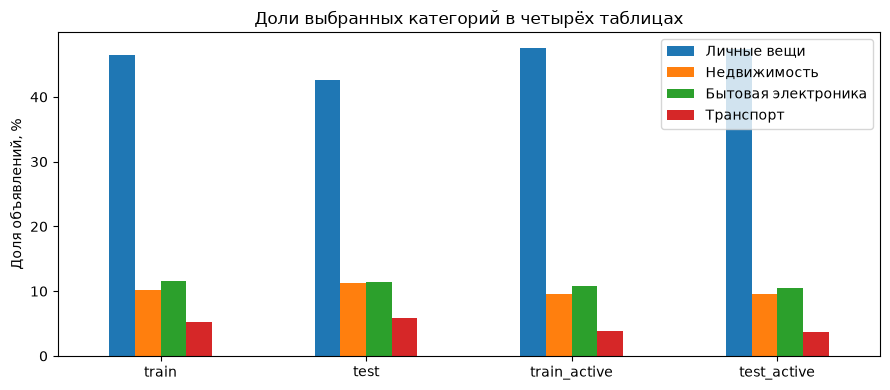

In [47]:
cats = {}
for name in ad_names:
    if name in extra:
        counts = extra[name]["categories"]
        total = extra[name]["rows"]
    else:
        data = train if name == "train" else test
        counts = data["parent_category_name"].value_counts().to_dict()
        total = len(data)
    cats[name] = {category: 100 * count / total for category, count in counts.items()}
shares = pd.DataFrame(cats).fillna(0)
display(shares.round(2))
shares.loc[["Личные вещи", "Недвижимость", "Бытовая электроника", "Транспорт"]].T.plot.bar(figsize=(9, 4))
plt.title("Доли выбранных категорий в четырёх таблицах")
plt.ylabel("Доля объявлений, %")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [48]:
price_rows = []
for name in ad_names:
    if name in extra:
        s = extra[name]
        sample = s["price_sample"].summary()
        price_rows.append({"Файл": name, "Нулевых цен": s["price_zero"],
                           "Максимум": s["price_max"],
                           "Медиана по выборке": sample["median_approx"],
                           "Размер выборки": sample["sample_size"]})
    else:
        data = train if name == "train" else test
        price_rows.append({"Файл": name, "Нулевых цен": int(data["price"].eq(0).sum()),
                           "Максимум": data["price"].max(),
                           "Медиана по выборке": data["price"].median(),
                           "Размер выборки": int(data["price"].notna().sum())})
display(pd.DataFrame(price_rows).set_index("Файл"))
print("Для train/test медианы точные; для *_active получены по выборкам.")


,Нулевых цен,Максимум,Медиана по выборке,Размер выборки
Файл,,,,
train,4646,7.950101e+10,1300.0,1418062
test,1924,3.000060e+09,1500.0,477853
train_active,552368,1.000000e+12,1000.0,86000
test_active,440546,1.000000e+11,1000.0,96300


Для train/test медианы точные; для *_active получены по выборкам.


## 9. Риски утечек и ограничения

- `activation_date` основных объявлений позволяет выполнить временную валидацию; общие продавцы требуют дополнительной проверки обобщения на новых пользователей.
- Прямой связи размеченных объявлений с `*_active` и `periods_*` по `item_id` нет. Для `*_active` также имеются повторные ключи.
- Объявления, встречающиеся в обоих `*_active`, имеют потенциально разные даты и атрибуты в двух снимках. Нельзя трактовать такие поля как неизменную историческую запись.
- В `periods_*` есть интервалы, которые заканчиваются не раньше дат основной выборки; агрегирование полных периодов без отсечения по моменту прогноза может раскрыть будущие события.
- Строки без обязательных атрибутов и нетипичные категории исключаются из кандидатов в историю. Причина их появления устанавливается адресным просмотром исходных строк выше; агрегаты сами по себе не доказывают сбой парсера.
- Для основного эксперимента дополнительные данные исключены, пока невозможно подтвердить временную доступность признаков. Фотографий в CSV нет; `image` представляет идентификатор.

## 10. Выводы для настройки AutoML

1. Цель `deal_probability` имеет непрерывные значения от 0 до 1; основная задача — регрессия с большой долей нулей. Метрика определяется постановкой пользователя, а не автоматически по доле нулей.
2. Основная воспроизводимая постановка использует `train` (обучение) и `test` (прогноз), без присоединения историй. `item_id` не используется как признак.
3. Для прогноза будущих объявлений требуется временная валидация по `activation_date`; отдельная групповая проверка оценивает перенос на новых продавцов.
4. AutoML должен учитывать структурные пропуски, категориальные признаки, русский текст, высокую кардинальность и крайние цены.
5. `*_active` и `periods_*` нельзя использовать для прямого объединения с основными таблицами. Допустим только отдельный эксперимент с проверенной точкой времени и историческими агрегатами продавца.
6. Для такого эксперимента нужны дедупликация по `item_id`, проверка согласованности `user_id`, отсечение по дате прогноза и одинаковое получение признаков для train/валидации/test. Истории с неподтверждённой доступностью исключаются.